# 論文の中心結果：同じ16,848時刻・8法人の3区分

固定年間版からの再集計だけです。新規LP・年間取得・指標変更はしません。
保存枠の有無と代替可否の関係を、同じ元需要・固定Rで比較します。
原TCRSIの再現、実増強効果、真の企業不可欠性・利益・売り渋りの認定ではありません。

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
REPORT = ROOT / "reports/28_paper_central_result"
QA = REPORT / "qa"
display(Markdown(f"報告: `{REPORT}`"))

LABELS = {
    "entity_ja": "法人",
    "comparison_times": "比較コマ数",
    "feasible_with_saved_bounds": "保存枠下でも成立",
    "feasible_only_without_bounds": "枠解除で成立",
    "infeasible_even_without_bounds": "解除しても不成立",
    "area": "地域",
    "central_category": "3区分",
    "variable": "変数",
    "category_ja": "区分の意味",
    "frames": "コマ数",
    "median": "中央値",
    "q25": "25%点",
    "q75": "75%点",
    "minimum": "最小",
    "maximum": "最大",
    "dimension": "構成の種類",
    "level": "区分",
    "pct": "構成比[%]",
    "annual_times": "年間コマ数",
    "annual_uncomputed": "年間倍率未算定",
    "annual_multiplier_valid": "年間倍率有効",
    "common_times": "共通時刻数",
    "common_uncomputed": "共通時刻の倍率未算定",
    "common_multiplier_valid": "共通時刻の倍率有効",
    "artifact": "図表",
    "placement": "配置",
    "purpose": "目的",
    "path": "参照先",
    "comparison_axis": "対照軸",
    "original_technical_reference": "原文",
    "current_diagnostic": "今回",
    "page_equation": "ページ・式",
    "interpretation": "解釈",
}


def show_table(name):
    frame = pd.read_csv(QA / name)
    if "central_category" in frame:
        frame["central_category"] = frame.central_category.replace(
            {
                key: LABELS[key]
                for key in [
                    "feasible_with_saved_bounds",
                    "feasible_only_without_bounds",
                    "infeasible_even_without_bounds",
                ]
            }
        )
    if name == "central_three_categories.csv":
        frame = frame[
            [
                "entity_ja",
                "comparison_times",
                "feasible_with_saved_bounds",
                "feasible_only_without_bounds",
                "infeasible_even_without_bounds",
            ]
        ]
    display(frame.rename(columns=LABELS))


show_table("central_three_categories.csv")
display(pd.Series(json.loads((QA / "aggregation_audit.json").read_text()), name="分母・結合QA"))

報告: `/Users/goto/Documents/Uni/04_research_second/reports/28_paper_central_result`

,法人,比較コマ数,保存枠下でも成立,枠解除で成立,解除しても不成立
0,北海道電力,16848,37,16811,0
1,東北電力,16848,15646,1202,0
2,JERA,16848,767,14220,1861
3,北陸電力,16848,127,16721,0
4,関西電力,16848,13698,3117,33
5,中国電力,16848,16824,24,0
6,四国電力,16848,16366,482,0
7,九州電力,16848,3894,12953,1


annual_company_frames                                  140160
common_company_frames                                  134784
company_count                                               8
annual_times                                            17520
common_times                                            16848
excluded_all_firms_infeasible_times                       624
excluded_network_input_times                               48
common_time_set_equal_for_all_companies                  True
jera                                       [767, 14220, 1861]
all_row_sums                                            16848
original_status_equivalence                              True
price_all_area_times                                   157680
price_common_area_times                                151632
join_rate                                                 1.0
unmatched                                                   0
row_multiplication                                          0
source_c

## 本文：方法図（人工例は実容量ではない）

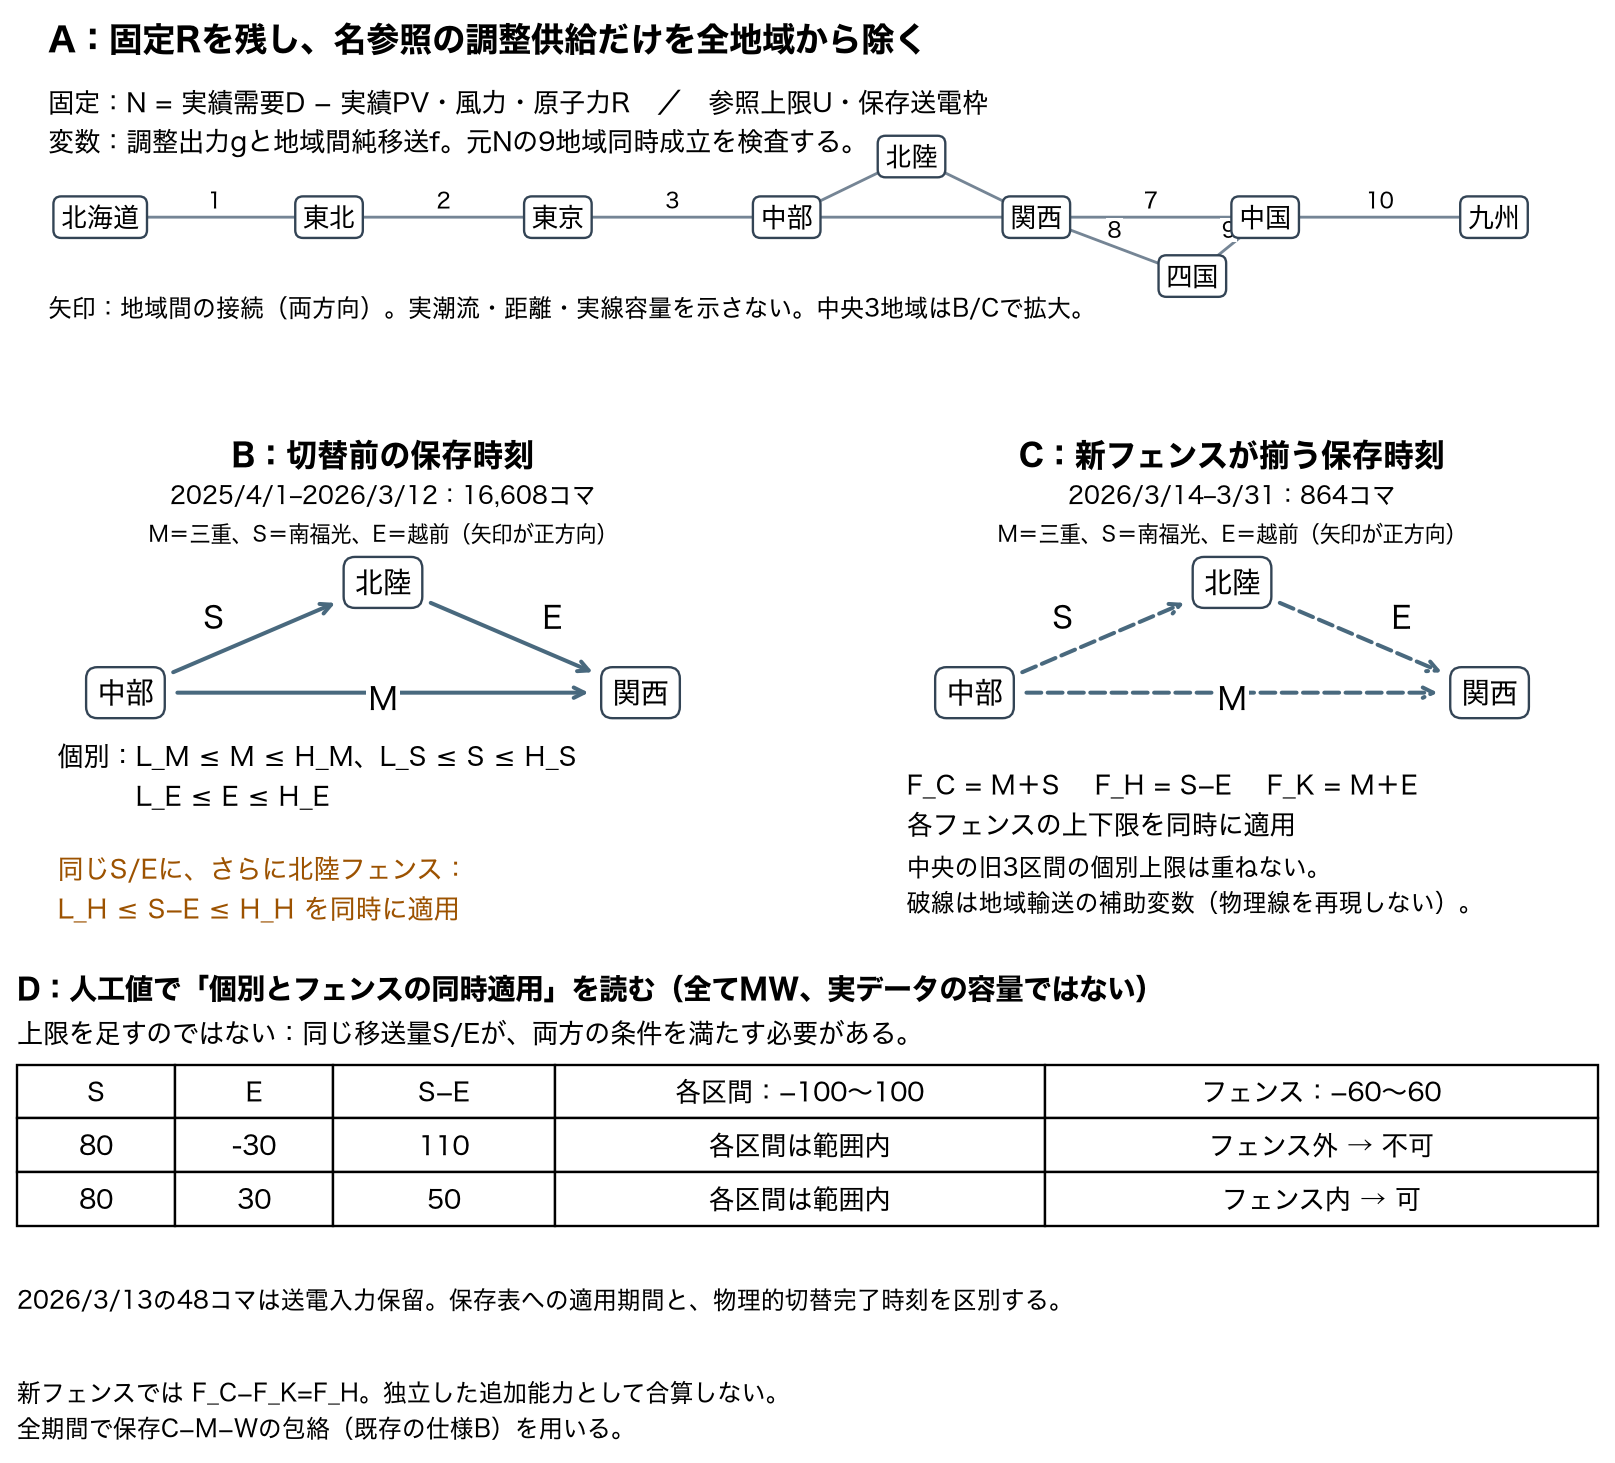

In [2]:
display(Image(filename=str(REPORT / "figures/01_method_readable.png")))

## 本文：排他的3区分（全法人不成立624・保留48は別）

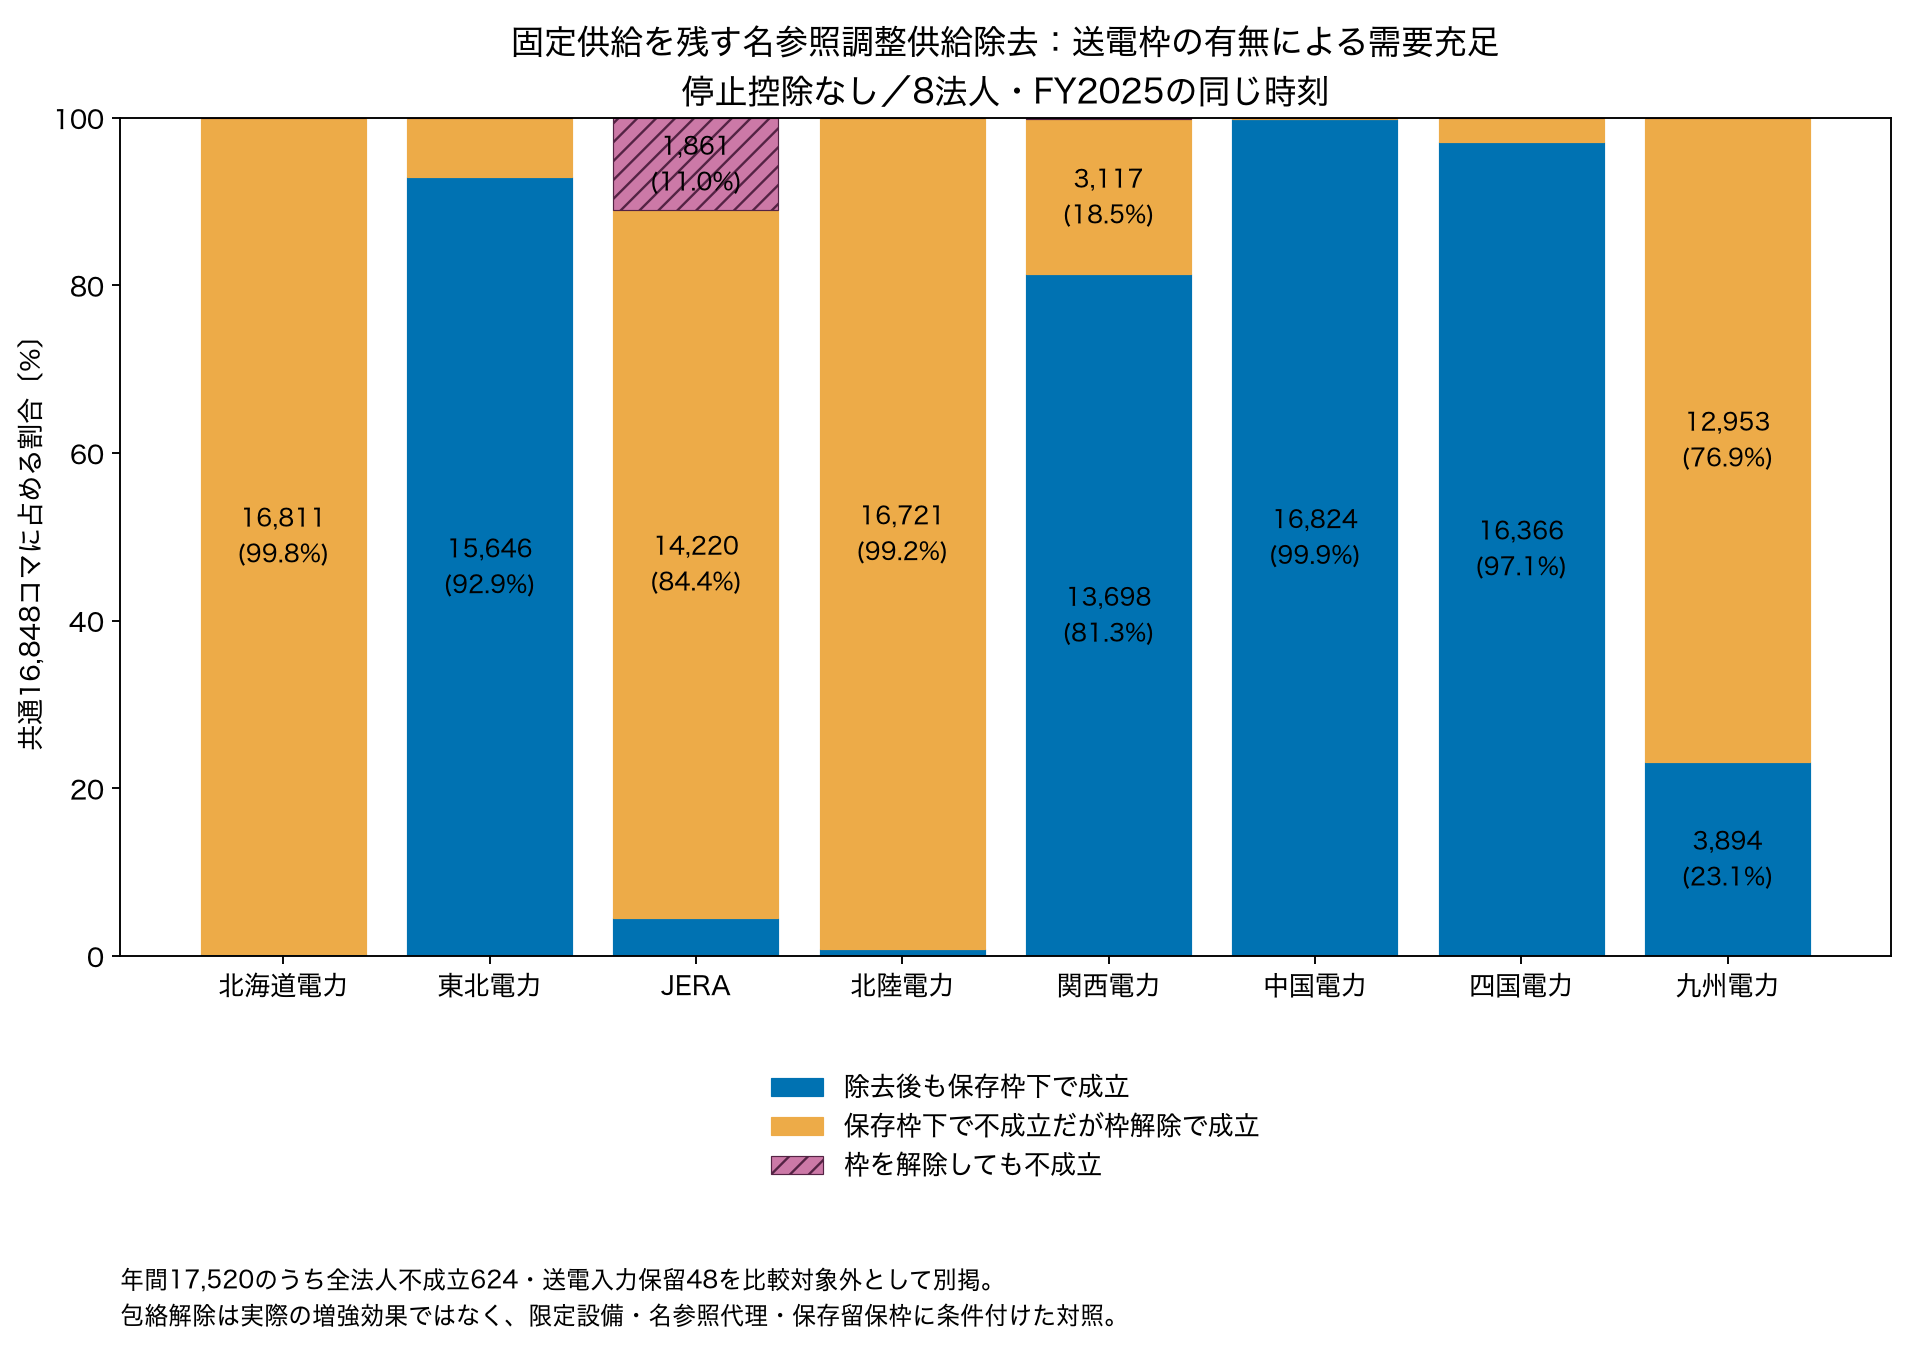

In [3]:
display(Image(filename=str(REPORT / "figures/02_central_three_categories.png")))

## 付録候補：同じ3区分の価格（構成差を必ず併記）

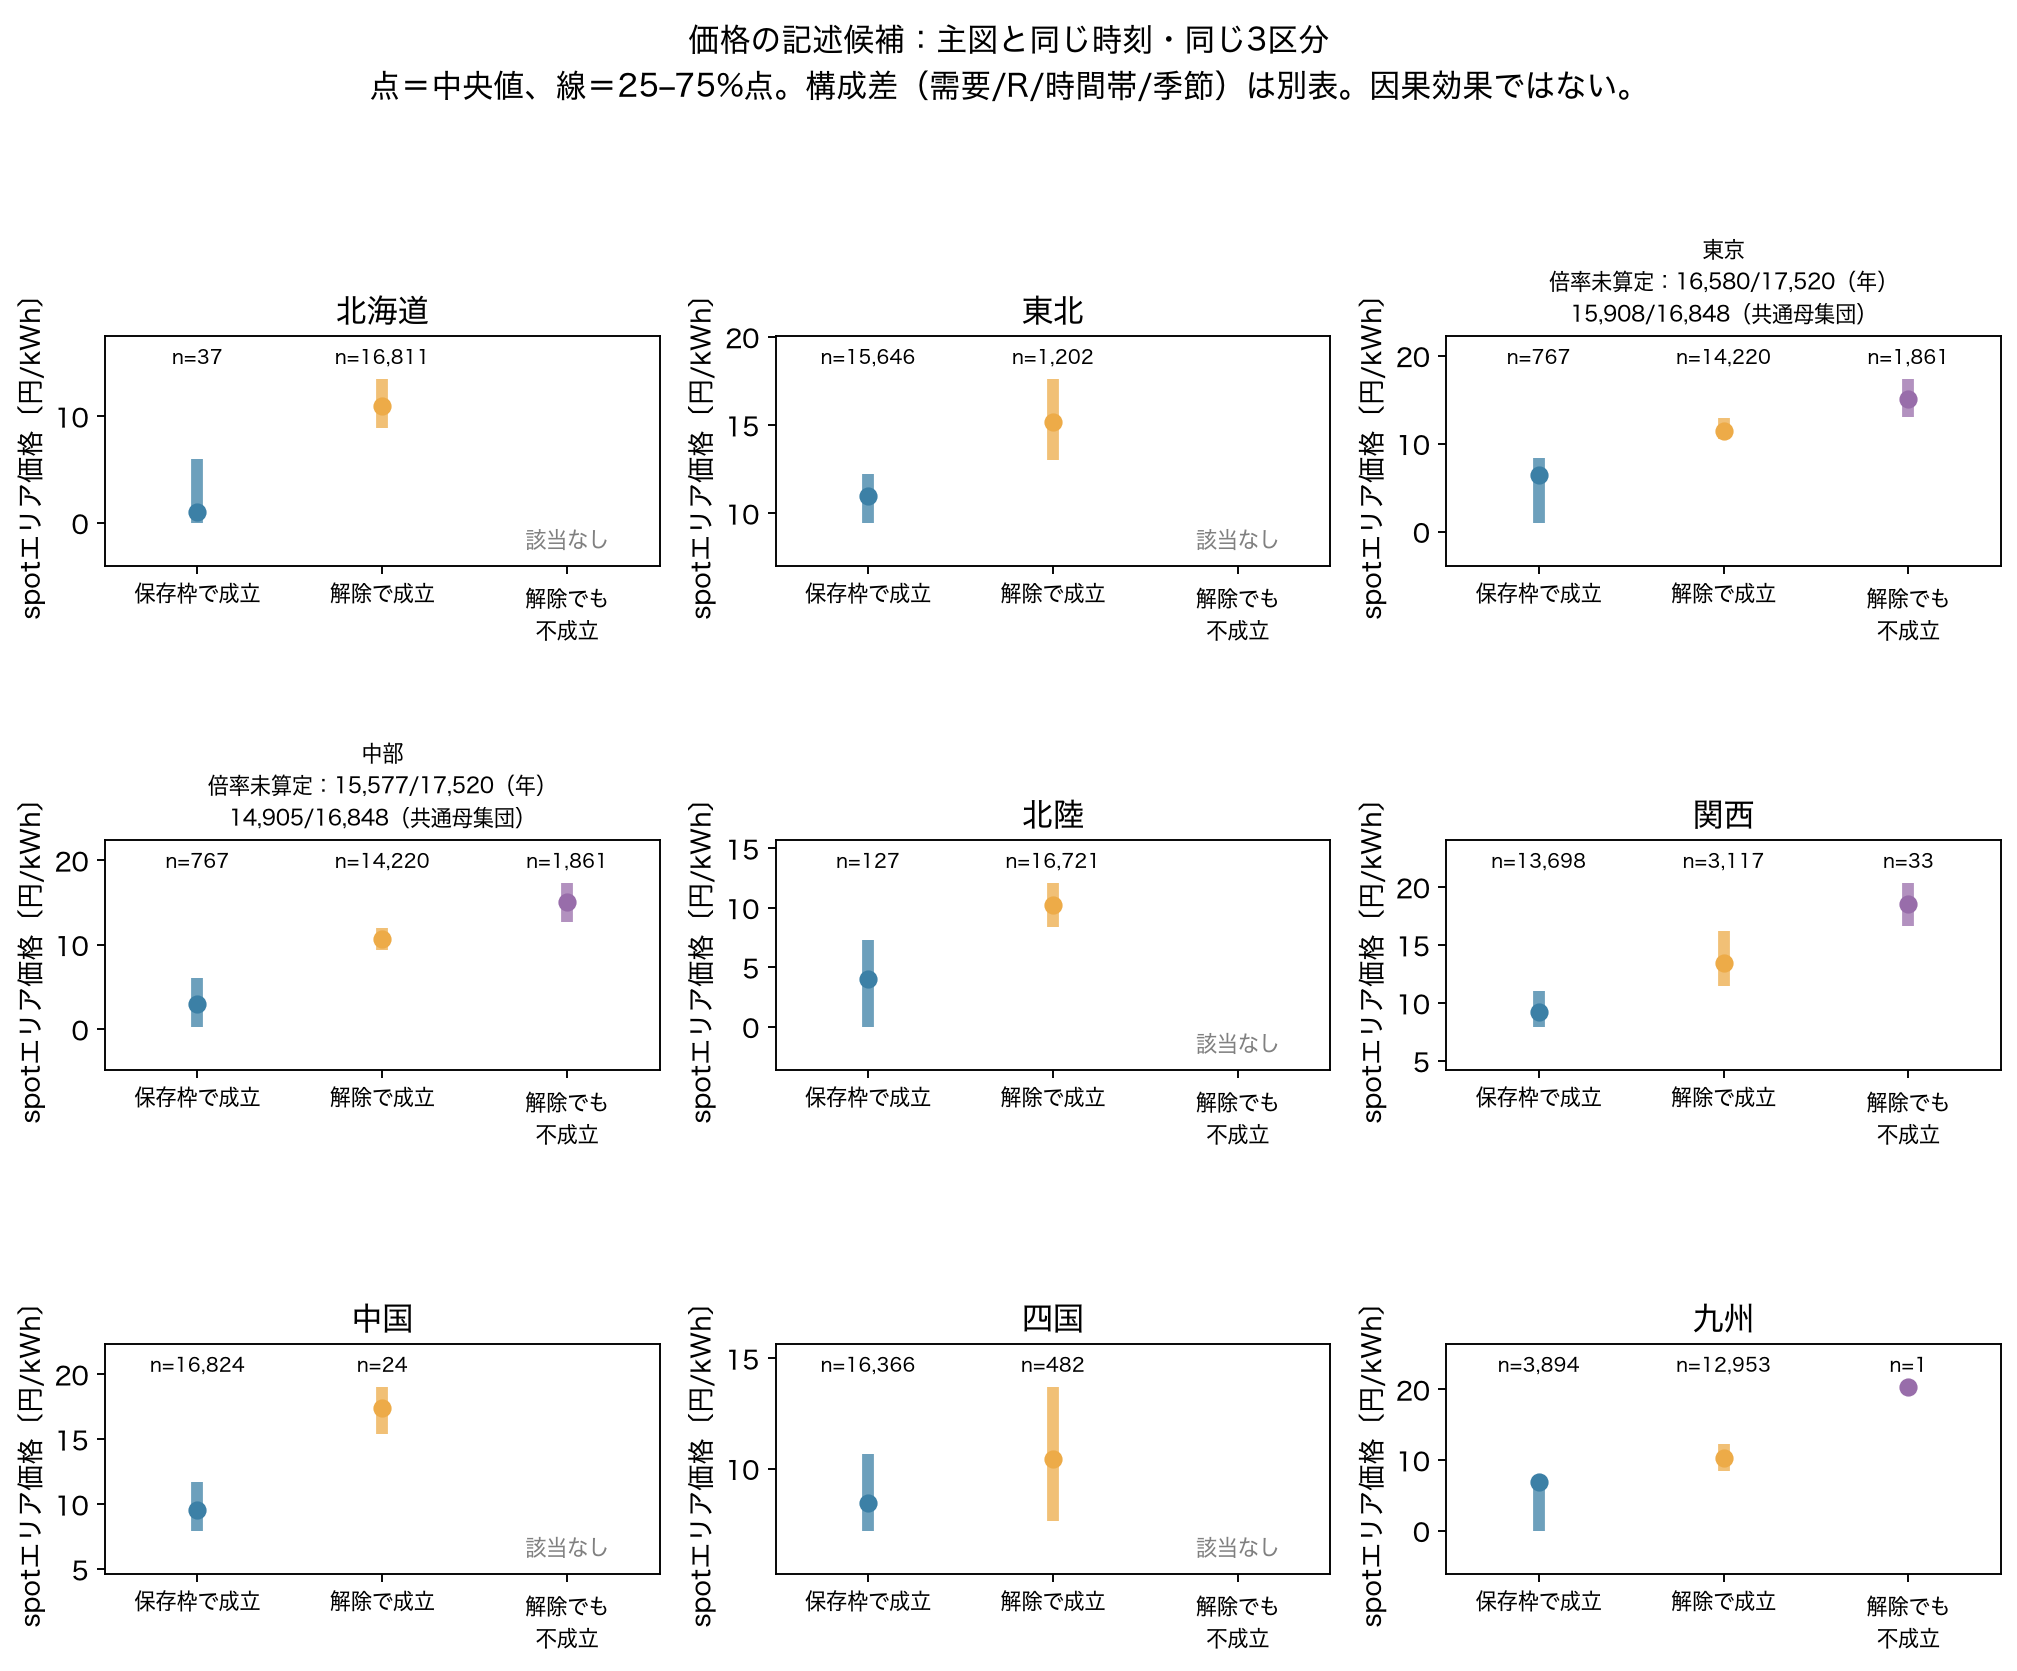

In [4]:
display(Image(filename=str(REPORT / "figures/A01_price_same_categories_candidate.png")))

## 価格と構成差・倍率未算定

価格だけを効果として読まないでください。D/R/N・時間帯・季節の構成は群ごとに異なります。
英語の実列名・元値は派生Parquetへ保存し、ここでは対応する数値表を表示します。

In [5]:
for name in [
    "price_demand_fixed_output_by_category.csv",
    "composition_by_season_time_month.csv",
    "multiplier_missing_in_same_view.csv",
    "main_appendix_reproduction.csv",
    "technical_reference_contrast.csv",
]:
    display(Markdown("### " + name))
    show_table(name)
display(
    Markdown(
        "元データ：`data/processed/paper_central_result/20261027_v1/`。旧年間版は変更していません。"
    )
)

### price_demand_fixed_output_by_category.csv

,地域,3区分,区分の意味,コマ数,変数,observed,missing,最小,25%点,中央値,75%点,最大
0,北海道,保存枠下でも成立,除去後も保存枠下で成立,37,area_price,37,0,0.01,0.01,1.01,6.00,7.17
1,北海道,保存枠下でも成立,除去後も保存枠下で成立,37,demand_actual_sample_mw,37,0,2546.00,2768.00,2856.00,2927.00,3338.00
2,北海道,保存枠下でも成立,除去後も保存枠下で成立,37,fixed_actual_mw,37,0,1953.00,2145.00,2198.00,2260.00,2503.00
3,北海道,保存枠下でも成立,除去後も保存枠下で成立,37,target_net_demand_mw,37,0,421.00,550.00,679.00,737.00,835.00
4,北海道,枠解除で成立,保存枠下で不成立だが枠解除で成立,16811,area_price,16811,0,0.01,8.90,10.93,13.49,80.00
...,...,...,...,...,...,...,...,...,...,...,...,...
103,九州,枠解除で成立,保存枠下で不成立だが枠解除で成立,12953,target_net_demand_mw,12953,0,3072.00,4750.00,5572.00,6596.00,11124.00
104,九州,解除しても不成立,枠を解除しても不成立,1,area_price,1,0,20.35,20.35,20.35,20.35,20.35
105,九州,解除しても不成立,枠を解除しても不成立,1,demand_actual_sample_mw,1,0,14614.00,14614.00,14614.00,14614.00,14614.00
106,九州,解除しても不成立,枠を解除しても不成立,1,fixed_actual_mw,1,0,3912.00,3912.00,3912.00,3912.00,3912.00


### composition_by_season_time_month.csv

,地域,3区分,構成の種類,区分,コマ数,category_frames,構成比[%]
0,北海道,保存枠下でも成立,season,春(3–5月),10,37,27.027027
1,北海道,保存枠下でも成立,season,夏(6–8月),15,37,40.540541
2,北海道,保存枠下でも成立,season,秋(9–11月),12,37,32.432432
3,北海道,保存枠下でも成立,season,冬(12–2月),0,37,0.000000
4,北海道,保存枠下でも成立,time_band,00–06時,0,37,0.000000
...,...,...,...,...,...,...,...
535,九州,解除しても不成立,month,2025-11,0,1,0.000000
536,九州,解除しても不成立,month,2025-12,0,1,0.000000
537,九州,解除しても不成立,month,2026-01,0,1,0.000000
538,九州,解除しても不成立,month,2026-02,0,1,0.000000


### multiplier_missing_in_same_view.csv

...

### main_appendix_reproduction.csv

,図表,配置,目的,参照先,denominator_or_limit
0,方法図（今回）,本文,固定/変数、除去、9地域、フェンスを初見で説明,figures/01_method_readable.pdf,新規編集。データ/LPは変更しない
1,排他的3区分（今回）,本文・中心結果,送電枠の有無で同じ元需要の代替可否が変わる部分を直接示す,figures/02_central_three_categories.pdf,"共通16,848、全法人不成立624/入力保留48を併記"
2,17条件一致図（工程27図2）,付録A・本文は重点数値のみ,中心図と異なる供給条件の幅を確認する,../27_fy2025_annual/figures/02_condition_consi...,"17条件共通全法人成立12,265。16,848へ混ぜない"
3,旧送電あり/なし2棒（工程27図3）,再現資料,中心3区分図が両結果と変化の内訳をまとめるため本文は重複,../27_fy2025_annual/figures/03_transmission_co...,旧図保持。新中心図と数値一致を検査
4,倍率と価格（工程27図4全範囲/拡大）,付録B・全範囲は再現資料にも,独自の地域倍率。特にJERAは未算定が多く主図を代表させない,../27_fy2025_annual/figures/04_multiplier_pric...,"東京940/17,520有効・16,580未算定、中部1,943有効・15,577未算定を同じ表へ"
5,同じ3区分の価格（今回）,付録候補。本文採用は保留,倍率未算定を落とさず中心図と同じ時刻で記述できる,figures/A01_price_same_categories_candidate.pdf,"9地域各16,848。D/R/時間帯/季節構成を隣接表へ。因果ではない"
6,月別図（工程27 A01）,付録C,年間の状態が季節・月でどれだけ変わるか,../27_fy2025_annual/figures/A01_monthly_status...,新3区分月別表も付ける。都合のよい月を選ばない
7,全17条件/全status/元入力/数式監査,再現資料,全時刻・理由・式/コード/データを追跡する,../27_fy2025_annual/qa/verification.json,旧固定manifestと今回の派生manifestを区別


### technical_reference_contrast.csv

,対照軸,原文,今回,ページ・式,解釈
0,需要倍率,全母線負荷dを同一倍率tで拡大し地理的比率を保つ。最大tをTCRSIとする,主図は倍率なしで全地域の元Nを固定。補助倍率は対象地域だけλN、他地域N固定,§4.1式14a–c・p16、§5.1図6/表3・pp19–20,異なる。局所倍率を原TCRSIと呼ばない
1,固定R,式14に独立した固定供給Rの項はない,PV・風力・原子力実績Rを分析上固定しN=D−R。対象法人分でもRは残す,§4.1式14b/d/e・p16,追加した会計/行動仮定。技術的調整不能の認定でない
2,除去する供給,当該企業に属する全発電機の利用可能供給を0とする,名参照の調整上限だけを全地域から除く。固定Rを除かず、実績Gを再控除しない,§4.1式14d/e・p16,一企業ずつ全地域除去は共通。除去範囲は異なる
3,ネットワーク,発電/負荷のshift factor行列H_g/H_dによるDC潮流制約,9地域の需給＋自由な純移送変数。区間/フェンス包絡を同時適用,§4.1式14c・p16、§5.1図6・p19,PTDF/Kirchhoff法則・地域内系統を再現しない
4,企業帰属,企業に所有される発電機集合。事例では所有/支配が入力,点検済みHJKS発電事業者名の代理。共同事業・売電/契約の支配は未確認,§4.1・p16、§5.2/5.3・pp20–21,JERAは一法人だが名参照代理。契約帰属を認定しない
5,送電/供給入力,送電上限b、発電機上限。事例では容量を供給可能量と仮定。ERCOTはSCOPF制約を選択,参照容量一定・17停止条件、保存C−M−W。切替後は新フェンスの地域カット,§5.2/5.3・p20（脚注4含む）,入力の仮定/範囲が異なる。原事例も全制約の完全性に留保
6,価格・利益,TCMPIは入札/OPFと利潤最大化仮定から平均マークアップを評価。TCRSIは誘因/利益を...,公開spot価格を記述的に併記する。費用/利益/行使やTCMPIを計算しない,§4.2・p17、§6・pp21–22、図7・p22,価格散布図は原図7のTCRSI–TCMPI比較ではない
7,ex ante/ex post,§6ではTCRSIは行動や清算結果を必須としない事前的指標、TCMPIは事後的。ERCOT入...,実績D/Rと後日保存資料による事後条件付き構造評価。入札時情報集合は再現しない,§5.3・p20、§6・pp21–22,構造を評価する点は共通でも情報時点は異なる


元データ：`data/processed/paper_central_result/20261027_v1/`。旧年間版は変更していません。